# Week 1 Deliverable — Custom CNN on CIFAR-10

This Google Colab notebook trains a **custom CNN from scratch** (no pretrained model) on CIFAR-10, logs training/validation metrics, plots loss and accuracy curves, saves the best checkpoint, and evaluates it on the official test set.

**Recommended:** In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU).

Outputs saved in `/content/outputs/`:
- `best_cnn.pth` — best checkpoint selected using validation accuracy
- `loss_curve.png` and `accuracy_curve.png` — training curves
- `metrics.json` — recorded results
- `training_history.csv` — metrics by epoch


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Check the runtime and install dependencies

In [2]:
!pip -q install wandb

import os
import random
import json
import time
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", DEVICE)


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Using: cuda


In [3]:
SEED = 42
EPOCHS = 30
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

DATA_DIR = Path("/content/data")
OUTPUT_DIR = Path("/content/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# CIFAR-10 channel statistics
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

print("Output directory:", OUTPUT_DIR)


Output directory: /content/outputs


In [5]:
import tarfile
from pathlib import Path

archive = Path(
    "/content/drive/MyDrive/datasets/cifar-10-python.tar.gz"
)
extract_dir = Path("/content/data")
extract_dir.mkdir(parents=True, exist_ok=True)

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(path=extract_dir)

print("Extracted:", list(extract_dir.iterdir()))

/tmp/ipykernel_430/3079369794.py:11: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


Extracted: [PosixPath('/content/data/cifar-10-batches-py')]


## 2. Define a custom CNN

In [6]:
class CIFAR10CNN(nn.Module):
    """Custom CNN for 32x32 RGB images; trained from scratch."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 32 -> 16

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 16 -> 8

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_preview = CIFAR10CNN()
sample = torch.randn(8, 3, 32, 32)
print("Input shape:", sample.shape)
print("Output shape:", model_preview(sample).shape)
print("Trainable parameters:", sum(p.numel() for p in model_preview.parameters() if p.requires_grad))
del model_preview, sample


Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 10])
Trainable parameters: 1608010


## 4. Download CIFAR-10 and create train/validation/test loaders

We use 45,000 images for training and 5,000 for validation. The official 10,000-image test set is held back until final evaluation. Random crop and horizontal flip are applied only to training images.

In [7]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_aug = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=False,
    transform=train_transform
)

train_eval = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=False,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    root="/content/data",
    train=False,
    download=False,
    transform=eval_transform
)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_aug), generator=generator).tolist()
train_indices, val_indices = indices[:45000], indices[45000:]

train_dataset = Subset(train_aug, train_indices)
val_dataset = Subset(train_eval, val_indices)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print(f"Train: {len(train_dataset):,} | Validation: {len(val_dataset):,} | Test: {len(test_dataset):,}")
print("Classes:", test_dataset.classes)


Train: 45,000 | Validation: 5,000 | Test: 10,000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 5. Optional: connect Weights & Biases (W&B)

In [10]:
# Set USE_WANDB = True and run this cell to log metrics online.
# Colab will ask you to authenticate with your W&B API key.
# If you prefer not to use W&B, leave USE_WANDB = False; local curves are still saved.

USE_WANDB = True
WANDB_PROJECT = "week1-ml-cv-foundations"

wandb_run = None
if USE_WANDB:
    import wandb
    wandb.login()
    wandb_run = wandb.init(
        project=WANDB_PROJECT,
        config={
            "architecture": "custom_cnn",
            "dataset": "CIFAR-10",
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "optimizer": "Adam",
            "seed": SEED,
            "train_examples": len(train_dataset),
            "validation_examples": len(val_dataset),
        },
    )

print("W&B enabled:", USE_WANDB)


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 1


wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://wandb.ai/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: aryan04-av (aryan04-av-delhi-technological-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B enabled: True


## 6. Train the model and log metrics

In [11]:
model = CIFAR10CNN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
}
best_val_acc = -1.0
best_epoch = 0
start_time = time.time()


def run_epoch(loader, training):
    model.train(training)
    total_loss, total_correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            n = labels.size(0)
            total_loss += loss.item() * n
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total += n

    return total_loss / total, total_correct / total


for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    lr_now = optimizer.param_groups[0]["lr"]
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f}, train acc={train_acc:.2%} | "
        f"val loss={val_loss:.4f}, val acc={val_acc:.2%} | lr={lr_now:g}"
    )

    if wandb_run is not None:
        wandb_run.log({
            "epoch": epoch,
            "train/loss": train_loss,
            "train/accuracy": train_acc,
            "validation/loss": val_loss,
            "validation/accuracy": val_acc,
            "learning_rate": lr_now,
        })

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save(model.state_dict(), OUTPUT_DIR / "best_cnn.pth")

    # Save history and curves each epoch so progress remains available.
    epochs_so_far = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs_so_far, history["train_loss"], label="Train")
    plt.plot(epochs_so_far, history["val_loss"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title("CIFAR-10 CNN — Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=160)
    plt.close()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs_so_far, [v * 100 for v in history["train_acc"]], label="Train")
    plt.plot(epochs_so_far, [v * 100 for v in history["val_acc"]], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("CIFAR-10 CNN — Accuracy")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "accuracy_curve.png", dpi=160)
    plt.close()

    with open(OUTPUT_DIR / "training_history.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "val_loss", "train_accuracy", "val_accuracy"])
        for i in range(len(history["train_loss"])):
            writer.writerow([
                i + 1, history["train_loss"][i], history["val_loss"][i],
                history["train_acc"][i], history["val_acc"][i]
            ])

print(f"Best validation accuracy: {best_val_acc:.2%} (epoch {best_epoch})")
print(f"Elapsed training time: {(time.time() - start_time) / 60:.1f} minutes")


Epoch 01/30 | train loss=1.6365, train acc=39.82% | val loss=1.1932, val acc=56.68% | lr=0.001
Epoch 02/30 | train loss=1.1970, train acc=56.92% | val loss=1.1257, val acc=58.78% | lr=0.001
Epoch 03/30 | train loss=1.0210, train acc=63.64% | val loss=0.8856, val acc=67.82% | lr=0.001
Epoch 04/30 | train loss=0.9105, train acc=68.02% | val loss=0.8658, val acc=69.38% | lr=0.001
Epoch 05/30 | train loss=0.8291, train acc=71.01% | val loss=0.7674, val acc=73.54% | lr=0.001
Epoch 06/30 | train loss=0.7657, train acc=73.63% | val loss=0.6483, val acc=77.04% | lr=0.001
Epoch 07/30 | train loss=0.7191, train acc=75.26% | val loss=0.6335, val acc=77.66% | lr=0.001
Epoch 08/30 | train loss=0.6713, train acc=76.94% | val loss=0.5802, val acc=80.12% | lr=0.001
Epoch 09/30 | train loss=0.6287, train acc=78.36% | val loss=0.6417, val acc=78.40% | lr=0.001
Epoch 10/30 | train loss=0.5998, train acc=79.64% | val loss=0.5455, val acc=81.40% | lr=0.001
Epoch 11/30 | train loss=0.5682, train acc=80.66% 

## 7. Evaluate the best checkpoint on the official test set

In [12]:
model.load_state_dict(torch.load(
    OUTPUT_DIR / "best_cnn.pth", map_location=DEVICE, weights_only=True
))
model.eval()

test_loss, test_acc = run_epoch(test_loader, training=False)

class_correct = torch.zeros(10, dtype=torch.long)
class_total = torch.zeros(10, dtype=torch.long)

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        predictions = model(images).argmax(dim=1)
        for label, prediction in zip(labels.cpu(), predictions.cpu()):
            class_total[label] += 1
            if label == prediction:
                class_correct[label] += 1

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2%}")
print("\nPer-class accuracy:")
for i, class_name in enumerate(test_dataset.classes):
    print(f"{class_name:12s}: {class_correct[i].item() / class_total[i].item():.2%}")

results = {
    "device": str(DEVICE),
    "epochs_completed": len(history["train_loss"]),
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_acc,
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "class_names": test_dataset.classes,
    "training_seconds": round(time.time() - start_time, 2),
    "model_checkpoint": "best_cnn.pth",
    "curves": ["loss_curve.png", "accuracy_curve.png"],
}
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

if wandb_run is not None:
    wandb_run.summary["best_validation_accuracy"] = best_val_acc
    wandb_run.summary["test_loss"] = test_loss
    wandb_run.summary["test_accuracy"] = test_acc
    wandb_run.finish()

print("\nSaved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", file.name)

if test_acc >= 0.70:
    print("\nSuccess gate passed: test accuracy is at least 70%.")
else:
    print("\n70% target not reached yet. Review the curves and tune using validation results.")


Test loss: 0.3539
Test accuracy: 88.79%

Per-class accuracy:
airplane    : 90.30%
automobile  : 95.20%
bird        : 84.90%
cat         : 84.20%
deer        : 85.70%
dog         : 82.80%
frog        : 91.20%
horse       : 88.20%
ship        : 94.20%
truck       : 91.20%


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,███████████████████████████▁▁▁
train/accuracy,▁▃▄▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇███████
train/loss,█▆▅▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁
validation/accuracy,▁▁▃▄▅▅▅▆▆▆▇▇▆▇▇▇▇▇▇▇▇▇▇█▇▇▇███
validation/loss,█▇▆▅▅▄▃▃▄▃▂▂▃▂▂▂▂▂▁▂▂▂▁▁▂▂▂▁▁▁
best_validation_accuracy,0.8966
epoch,30
learning_rate,0.0005
test_accuracy,0.8879
test_loss,0.35393



Saved files:
 - accuracy_curve.png
 - best_cnn.pth
 - loss_curve.png
 - metrics.json
 - training_history.csv

Success gate passed: test accuracy is at least 70%.


## 8. Display the logged curves

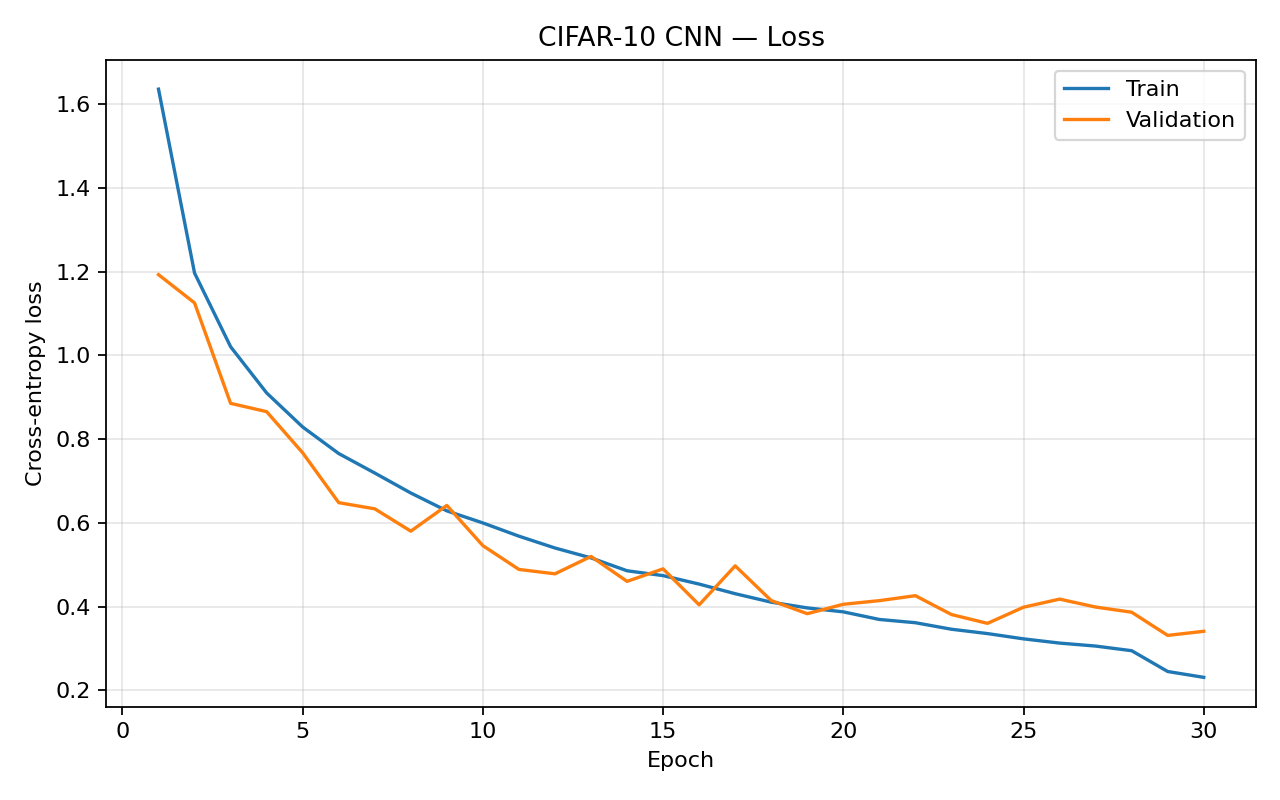

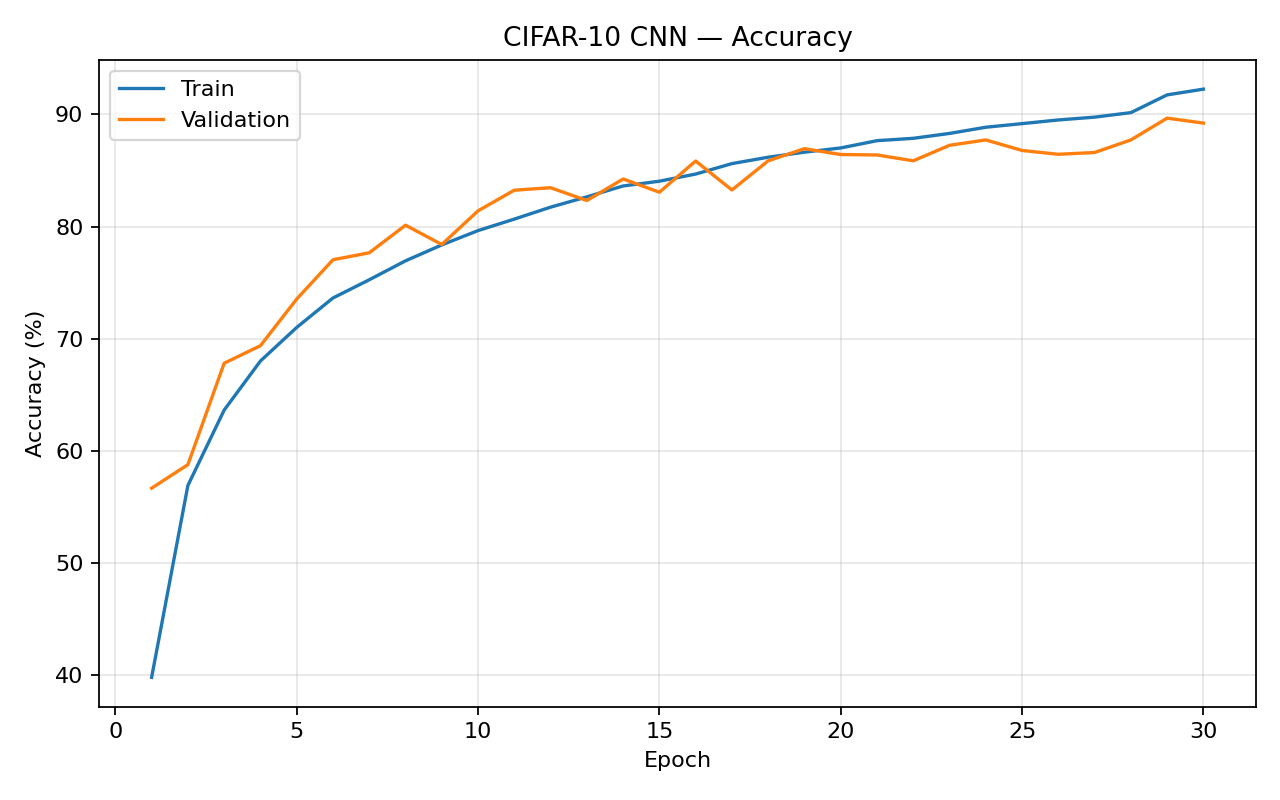

In [13]:
from IPython.display import Image, display

display(Image(filename=str(OUTPUT_DIR / "loss_curve.png")))
display(Image(filename=str(OUTPUT_DIR / "accuracy_curve.png")))


## 9. Download deliverables

Run this cell to download a ZIP containing the checkpoint, plots, metrics, and CSV history. Keep in mind that Colab's local files may disappear when its runtime resets.

In [14]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/cifar10_cnn_outputs",
    "zip",
    root_dir=str(OUTPUT_DIR)
)
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>